# EDA marketplace

Marketplace - домен с действиями пользователей над товарами: просмотрами, кликами, переходами и лайками.

Основные файлы в `dataset/small/`:

| Файл | Что хранится |
|---|---|
| `marketplace/events/{day}.pq` | События за один день: пользователь, товар, время, действие, поверхность и ОС |
| `marketplace/items.pq` | Товары: ID, бренд, категория, подкатегория, цена и эмбеддинг |
| `users.pq` | Общая таблица пользователей: ID, регион и соцдем-кластер |
| `brands.pq` | Общая таблица брендов: ID и эмбеддинги |

Для сравнения дополнительно используем `retail/events/*.pq`, `offers/events/*.pq`, их каталоги `items.pq` и отзывы о брендах `reviews/*.pq`.

In [1]:
import os
import glob

import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display
from huggingface_hub import snapshot_download

DOWNLOAD_DIR = "t_ecd_data"
DATASET_PATH = os.path.join(DOWNLOAD_DIR, "dataset", "small")
plt.rcParams["figure.figsize"] = (12, 5)

## 1. Скачивание данных


Скачивание домена marketplace

In [2]:
snapshot_download(
  repo_id="t-tech/T-ECD",
  repo_type="dataset",
  local_dir=DOWNLOAD_DIR,
  allow_patterns=["dataset/small/marketplace/*", "dataset/small/users.pq", "dataset/small/brands.pq"],
  max_workers=2,
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 230 files:   0%|          | 0/230 [00:00<?, ?it/s]

'/content/t_ecd_data'

Скачивание остальных доменов: retail, offers, reviews

In [3]:
snapshot_download(
  repo_id="t-tech/T-ECD",
  repo_type="dataset",
  local_dir=DOWNLOAD_DIR,
  allow_patterns=["dataset/small/retail/*", "dataset/small/offers/*", "dataset/small/reviews/*"],
  max_workers=2,
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 683 files:   0%|          | 0/683 [00:00<?, ?it/s]

'/content/t_ecd_data'

Подключаем файлы событий.

In [4]:
events_path = os.path.join(DATASET_PATH, "marketplace", "events", "*.pq")
events_files = glob.glob(events_path)
lazy_events = pl.scan_parquet(events_files)

Читаем таблицы пользователей, брендов и товаров без эмбеддингов.

In [5]:
items_path = os.path.join(DATASET_PATH, "marketplace", "items.pq")
item_columns = ["item_id", "brand_id", "category", "subcategory", "price"]
df_items = pl.read_parquet(items_path, columns=item_columns)
df_users = pl.read_parquet(os.path.join(DATASET_PATH, "users.pq"))
df_brands = pl.read_parquet(os.path.join(DATASET_PATH, "brands.pq"))

print("Товаров:", df_items.height)
print("Столбцы событий и их типы:", lazy_events.collect_schema())

Товаров: 2325409
Столбцы событий и их типы: Schema({'timestamp': Duration(time_unit='us'), 'user_id': UInt64, 'item_id': String, 'subdomain': String, 'action_type': String, 'os': String})


Первые 5 событий

In [6]:
display(lazy_events.head(5).collect())

timestamp,user_id,item_id,subdomain,action_type,os
duration[μs],u64,str,str,str,str
1096d 961527µs,43437058,"""nfmcg_24916338""","""search""","""view""","""android"""
1096d 1s 111847µs,12490292,"""nfmcg_13405584""","""u2i""","""view""","""android"""
1096d 1s 563138µs,25921728,"""nfmcg_13757063""","""u2i""","""view""","""ios"""
1096d 1s 768613µs,57351467,"""nfmcg_18843173""","""u2i""","""view""","""android"""
1096d 1s 900833µs,3083807,"""nfmcg_26053389""","""u2i""","""view""","""android"""


Первые 5 товаров

In [7]:
display(df_items.head(5))

item_id,brand_id,category,subcategory,price
str,u64,str,str,f64
"""nfmcg_10000001""",137356,null,null,6.06364
"""nfmcg_10000012""",53389,null,null,0.960436
"""nfmcg_1000002""",34153,"""Fashion Accessories, Tech Add-…","""Hats, Scarves, and Shawls""",-1.793113
"""nfmcg_10000034""",39543,null,null,3.416755
"""nfmcg_10000039""",82320,"""Fashion Accessories, Tech Add-…","""Jewelry and Costume Jewelry""",4.293433


## 2. Пропуски


Пропуски в событиях.

In [8]:
n_raw = lazy_events.select(pl.len()).collect(engine="streaming").item()
print("Событий до очистки пропусков:", n_raw)

event_nulls = lazy_events.select(pl.all().null_count()).collect(engine="streaming")
for column in event_nulls.columns:
  count = event_nulls[0, column]
  print(f"{column}: {count} пропусков, {round(count / n_raw * 100,2)}% доля")

Событий до очистки пропусков: 130447117
timestamp: 0 пропусков, 0.0% доля
user_id: 0 пропусков, 0.0% доля
item_id: 0 пропусков, 0.0% доля
subdomain: 41792 пропусков, 0.03% доля
action_type: 0 пропусков, 0.0% доля
os: 0 пропусков, 0.0% доля


Пропуски в таблице товаров (для эмбеддингов проверяем только наличие).

In [9]:
item_nulls = df_items.null_count()
for column in df_items.columns:
  count = item_nulls[0, column]
  print(f"{column}: {count} пропусков, {round(count / df_items.height * 100, 2)}% доля")

missing_embeddings = pl.scan_parquet(items_path).select(pl.col("embedding").null_count()).collect().item()
print("Товаров без эмбеддинга:", missing_embeddings)

item_id: 0 пропусков, 0.0% доля
brand_id: 0 пропусков, 0.0% доля
category: 966395 пропусков, 41.56% доля
subcategory: 1233023 пропусков, 53.02% доля
price: 2882 пропусков, 0.12% доля
Товаров без эмбеддинга: 73


Смотрим у каких действий не указана поверхность

In [10]:
missing_subdomain = lazy_events.filter(pl.col("subdomain").is_null())
missing_by_action = missing_subdomain.group_by("action_type").len()
missing_by_action = missing_by_action.collect(engine="streaming")
display(missing_by_action)

action_type,len
str,u32
"""like""",41792


Убираем события без обязательных полей ("user_id", "item_id", "timestamp", "action_type")

In [11]:
lazy_events = lazy_events.drop_nulls(["user_id", "item_id", "timestamp", "action_type"])
lazy_events = lazy_events.filter(pl.col("item_id").str.strip_chars() != "")
lazy_events = lazy_events.filter(pl.col("action_type").str.strip_chars() != "")
n_events = lazy_events.select(pl.len()).collect(engine="streaming").item()
print("Исключено событий:", n_raw - n_events)

Исключено событий: 0


Получаем пользователей marketplace и проверяем их наличие в таблице.

In [12]:
marketplace_users = lazy_events.select("user_id").unique().collect(engine="streaming")
known_users = df_users.select("user_id").drop_nulls().unique()
missing_users = marketplace_users.join(known_users, on="user_id", how="anti")
print("Пользователей marketplace:", marketplace_users.height)
print("Из них отсутствуют в users.pq:", missing_users.height)

Пользователей marketplace: 1616763
Из них отсутствуют в users.pq: 0


Оставляем в таблице только пользователей marketplace.

In [13]:
df_users = df_users.join(marketplace_users, on="user_id", how="semi")
display(df_users.head(5))

user_id,socdem_cluster,region
u64,u8,u8
54241043,17,58
11711313,7,23
32701128,0,11
27464232,17,38
57976173,20,2


Получаем бренды товаров marketplace и проверяем их наличие в таблице.

In [14]:
marketplace_brands = df_items.select("brand_id").drop_nulls().unique()
known_brands = df_brands.select("brand_id").drop_nulls().unique()
missing_brands = marketplace_brands.join(known_brands, on="brand_id", how="anti")
print("Брендов в каталоге marketplace:", marketplace_brands.height)
print("Из них отсутствуют в brands.pq:", missing_brands.height)

Брендов в каталоге marketplace: 231
Из них отсутствуют в brands.pq: 0


Оставляем в таблице только бренды marketplace.

In [15]:
df_brands = df_brands.join(marketplace_brands, on="brand_id", how="semi")
print("Строк таблицы для брендов marketplace:", df_brands.height)

Строк таблицы для брендов marketplace: 236


Пропуски в таблице пользователей marketplace

In [16]:
user_nulls = df_users.null_count()
for column in df_users.columns:
  count = user_nulls[0, column]
  print(f"{column}: {count} пропусков, {round(count / df_users.height * 100, 2)}% доля")

user_id: 0 пропусков, 0.0% доля
socdem_cluster: 3517 пропусков, 0.22% доля
region: 22182 пропусков, 1.37% доля


Пропуски в строках таблицы брендов marketplace

In [17]:
brand_nulls = df_brands.null_count()
for column in df_brands.columns:
  count = brand_nulls[0, column]
  print(f"{column}: {count} пропусков, {round(count / df_brands.height * 100, 2)}% строк")

brand_id: 0 пропусков, 0.0% строк
embedding: 192 пропусков, 81.36% строк


## 3. Дубликаты

Проверяем, повторяются ли ID товаров.

In [18]:
item_duplicates = df_items.group_by("item_id").len()
item_duplicates = item_duplicates.filter(pl.col("len") > 1)
print("Повторяющихся item_id:", item_duplicates.height)
display(item_duplicates.head(10))

Повторяющихся item_id: 0


item_id,len
str,u32


Проверяем повторяющиеся ID пользователей marketplace.

In [19]:
user_duplicates = df_users.group_by("user_id").len()
user_duplicates = user_duplicates.filter(pl.col("len") > 1)
print("Повторяющихся user_id:", user_duplicates.height)
display(user_duplicates.head(10))

Повторяющихся user_id: 0


user_id,len
u64,u32


Проверяем повторяющиеся ID брендов marketplace.

In [20]:
brand_duplicates = df_brands.group_by("brand_id").len()
brand_duplicates = brand_duplicates.filter(pl.col("len") > 1)
print("Повторяющихся brand_id:", brand_duplicates.height)
display(brand_duplicates)

Повторяющихся brand_id: 1


brand_id,len
u64,u32
37799,6


Смотрим записи повторяющегося бренда и сравниваем эмбеддинги.

In [21]:
brand_rows = df_brands.filter(pl.col("brand_id") == 37799)
display(brand_rows)

print("Всего строк:", brand_rows.height)
print("Полных дублей:", brand_rows.height - brand_rows.unique().height)
print("Строк без эмбеддинга:", brand_rows["embedding"].null_count())
print("Разных непустых эмбеддингов:", brand_rows["embedding"].drop_nulls().n_unique())

brand_id,embedding
u64,"array[f32, 300]"
37799,"[-0.104787, 0.0138, … 0.068517]"
37799,"[-0.101765, 0.001566, … 0.089219]"
37799,"[-0.088603, 0.040422, … 0.083506]"
37799,null
37799,"[-0.081444, 0.028631, … 0.080152]"
37799,"[-0.095465, 0.006346, … 0.073393]"


Всего строк: 6
Полных дублей: 0
Строк без эмбеддинга: 1
Разных непустых эмбеддингов: 5


Считаем полные дубликаты событий отдельно в каждом файле.

In [22]:
duplicate_rows = []
for file in events_files:
  df_day = pl.read_parquet(file)
  extra_rows = df_day.height - df_day.unique().height
  duplicate_rows.append({
    "file": os.path.basename(file),
    "duplicates": extra_rows,
    "min_time": df_day["timestamp"].min(),
    "max_time": df_day["timestamp"].max(),
    "null_time": df_day["timestamp"].null_count(),
  })
  del df_day

Смотрим, в каких файлах нашлись дубликаты.

In [23]:
duplicate_days = pl.DataFrame(duplicate_rows).sort("min_time")
print("Лишних одинаковых событий внутри файлов:", duplicate_days["duplicates"].sum())
display(duplicate_days.filter(pl.col("duplicates") > 0))

Лишних одинаковых событий внутри файлов: 0


file,duplicates,min_time,max_time,null_time
str,i64,duration[μs],duration[μs],i64


Проверяем пересечение временных диапазонов файлов.

In [24]:
separate = True
previous_max = None
for row in duplicate_days.iter_rows(named=True):
  if row["min_time"] is None:
    continue
  if previous_max is not None and row["min_time"] <= previous_max:
    separate = False
  if previous_max is None or row["max_time"] > previous_max:
    previous_max = row["max_time"]

print("Между файлами дубли исключены по времени:", separate and duplicate_days["null_time"].sum() == 0)

Между файлами дубли исключены по времени: True


## 4. Распределения признаков

Считаем количество действий и их доли.

In [25]:
action_counts = lazy_events.group_by("action_type").len().collect(engine="streaming")
action_counts = action_counts.sort("len", descending=True)
action_counts = action_counts.with_columns((pl.col("len") / n_events).alias("share"))
display(action_counts)

action_type,len,share
str,u32,f64
"""view""",126147783,0.967042
"""click""",3772094,0.028917
"""clickout""",485448,0.003721
"""like""",41792,0.00032


Сравниваем количество разных действий на графике.

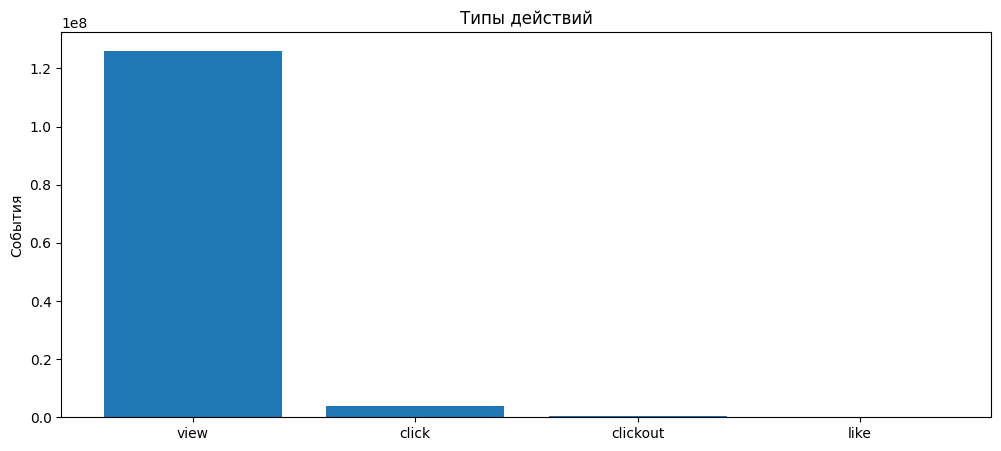

In [26]:
plt.bar(action_counts["action_type"].to_list(), action_counts["len"].to_list())
plt.title("Типы действий")
plt.ylabel("События")
plt.show()

Считаем события по поверхностям.

In [27]:
subdomain_counts = lazy_events.group_by("subdomain").len().collect(engine="streaming")
subdomain_counts = subdomain_counts.sort("len", descending=True)
subdomain_counts = subdomain_counts.with_columns((pl.col("len") / n_events).alias("share"))
display(subdomain_counts)

subdomain,len,share
str,u32,f64
"""u2i""",79321588,0.608075
"""other""",16115170,0.123538
"""catalog""",15741950,0.120677
"""search""",10457687,0.080168
"""i2i""",8768930,0.067222
null,41792,0.00032


Показываем распределение событий по поверхностям.

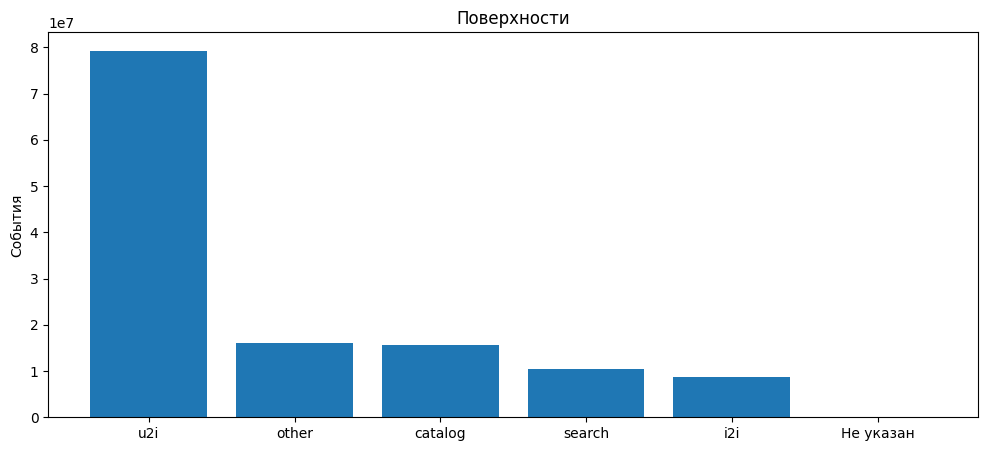

In [28]:
labels = subdomain_counts["subdomain"].fill_null("Не указан").to_list()
plt.bar(labels, subdomain_counts["len"].to_list())
plt.title("Поверхности")
plt.ylabel("События")
plt.show()

Смотрим количество событий и их доли по операционным системам.

os,len,share
str,u32,f64
"""android""",94889964,0.727421
"""ios""",25769133,0.197545
"""other""",9788020,0.075034


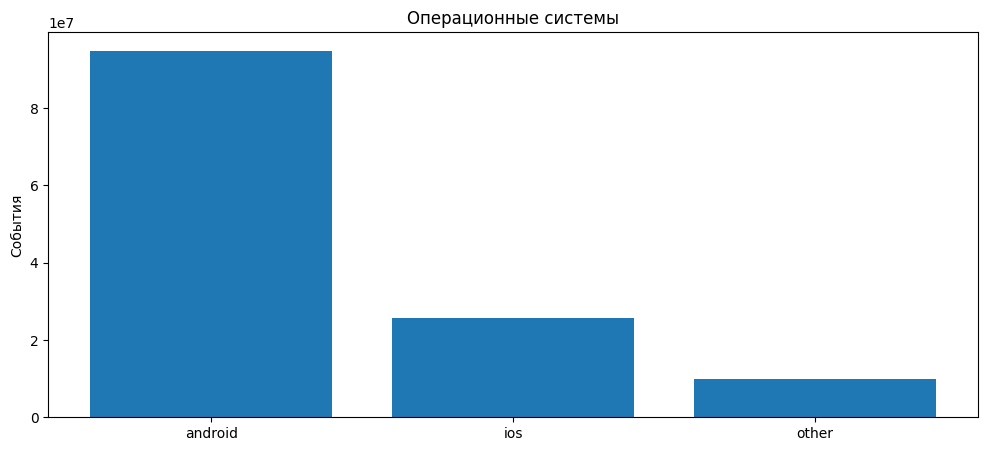

In [29]:
os_counts = lazy_events.group_by("os").len().collect(engine="streaming")
os_counts = os_counts.sort("len", descending=True)
os_counts = os_counts.with_columns((pl.col("len") / n_events).alias("share"))
display(os_counts)
plt.bar(os_counts["os"].fill_null("Не указана").to_list(), os_counts["len"].to_list())
plt.title("Операционные системы")
plt.ylabel("События")
plt.show()

Смотрим число событий по дням.

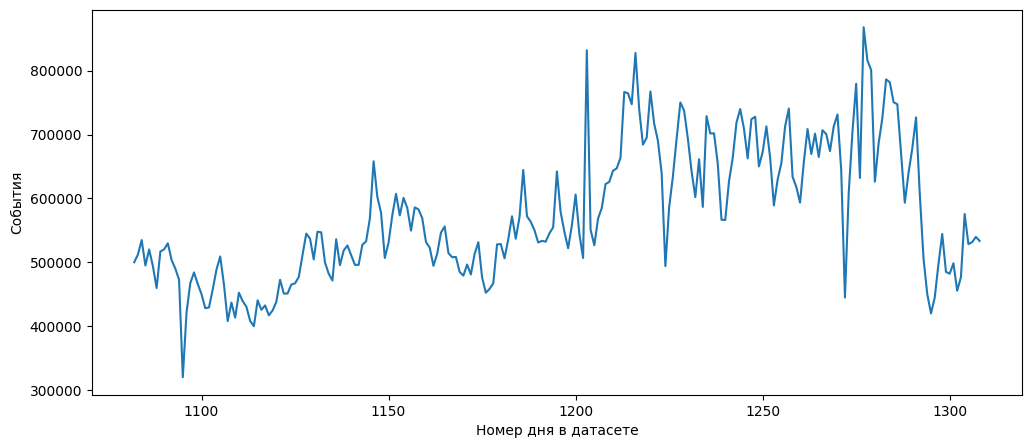

In [30]:
events_with_day = lazy_events.with_columns(pl.col("timestamp").dt.total_days().alias("day"))
daily = events_with_day.group_by("day").len().collect(engine="streaming")
daily = daily.sort("day")
plt.plot(daily["day"].to_list(), daily["len"].to_list())
plt.xlabel("Номер дня в датасете")
plt.ylabel("События")
plt.show()

Показываем 15 самых частых категорий, подкатегорий и брендов в каталоге.

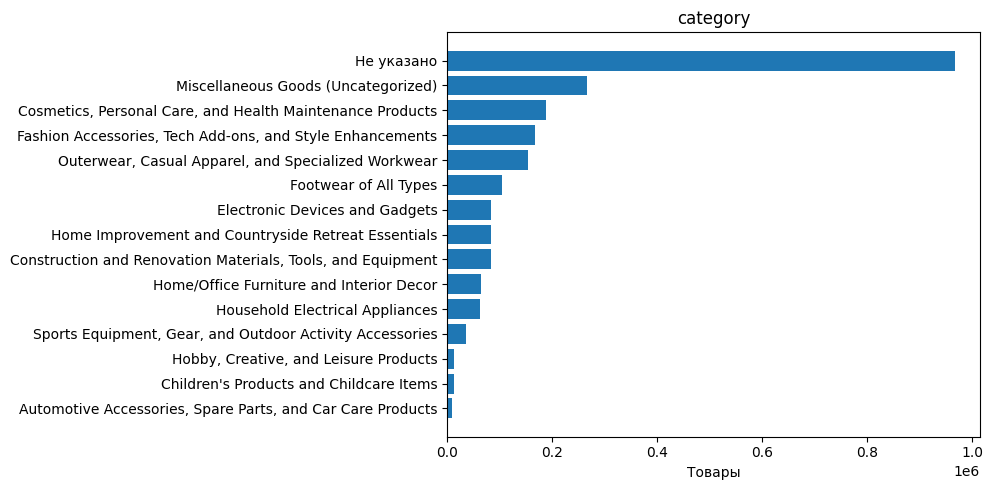

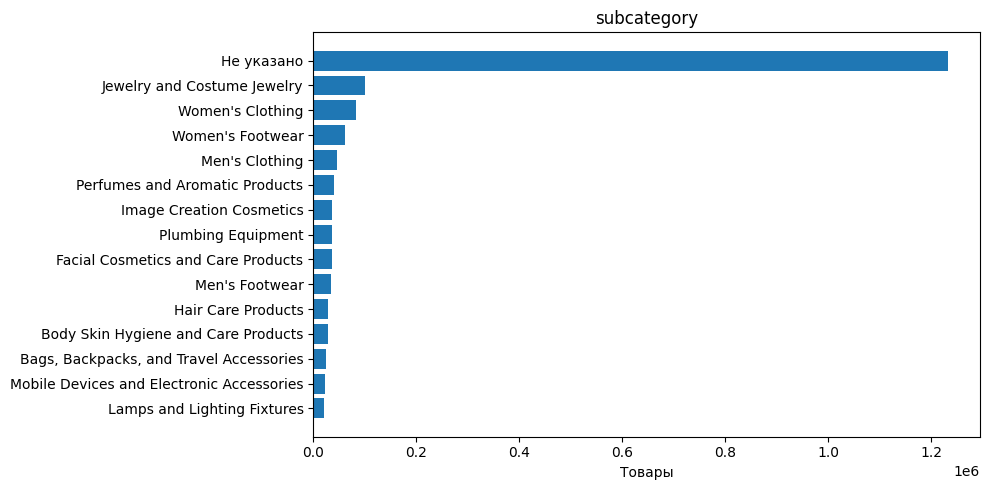

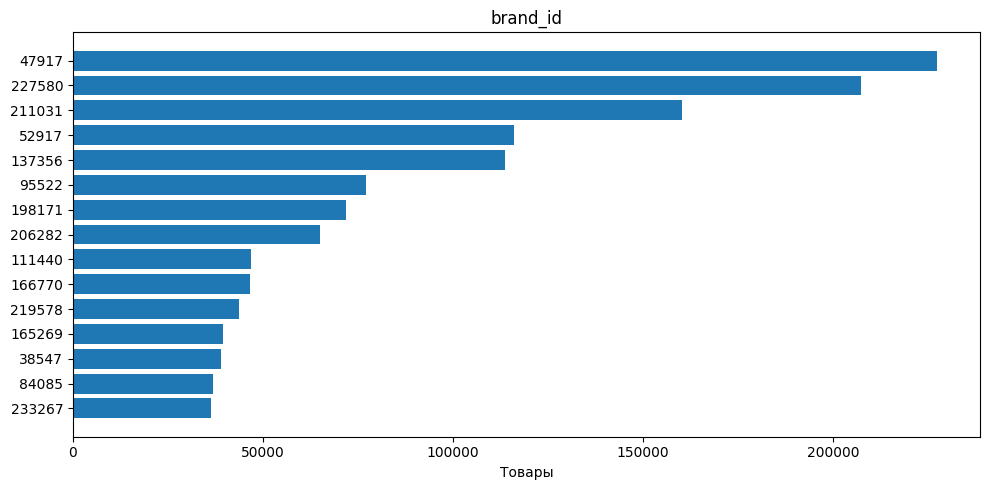

In [31]:
for column in ["category", "subcategory", "brand_id"]:
  counts = df_items.group_by(column).len()
  counts = counts.sort("len", descending=True).head(15)
  labels = counts[column].cast(pl.String).fill_null("Не указано").to_list()
  plt.figure(figsize=(10, 5))
  plt.barh(labels, counts["len"].to_list())
  plt.gca().invert_yaxis()
  plt.title(column)
  plt.xlabel("Товары")
  plt.tight_layout()
  plt.show()

Смотрим распределение цены без пропусков, NaN и бесконечностей.

statistic,value
str,f64
"""count""",2.322527e6
"""null_count""",0.0
"""mean""",0.489804
"""std""",2.455037
"""min""",-10.0
"""25%""",-1.219739
"""50%""",0.425758
"""75%""",2.194017
"""max""",10.0


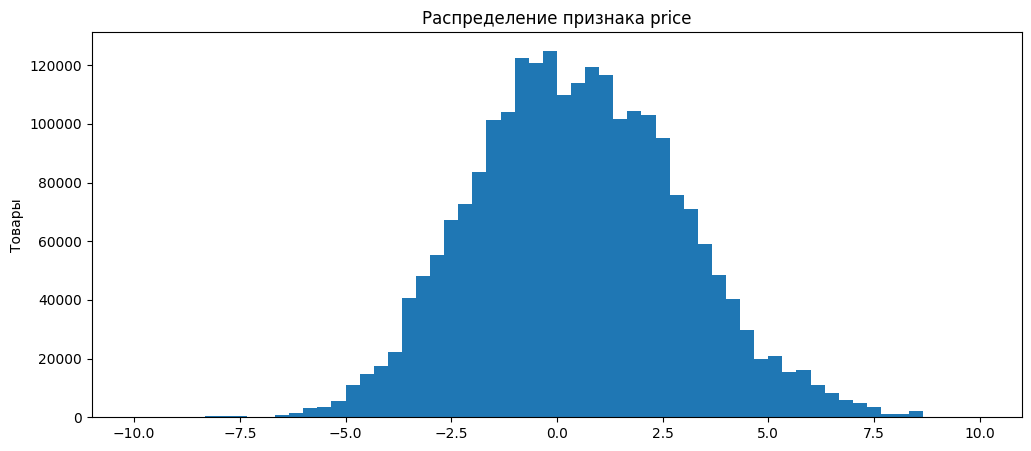

In [32]:
price = df_items.filter(pl.col("price").is_finite())["price"]
display(price.describe())
plt.hist(price.to_numpy(), bins=60)
plt.title("Распределение признака price")
plt.ylabel("Товары")
plt.show()

## 5. RecSys EDA

Считаем количество событий и кликов у каждого пользователя.

In [33]:
user_stats = lazy_events.group_by("user_id").agg(
  pl.len().alias("n_events"),
  (pl.col("action_type") == "click").sum().alias("n_clicks"),
).collect(engine="streaming")
display(user_stats.select("n_events", "n_clicks").describe())

statistic,n_events,n_clicks
str,f64,f64
"""count""",1.616763e6,1.616763e6
"""null_count""",0.0,0.0
"""mean""",80.684131,2.333115
"""std""",160.008893,6.641962
"""min""",1.0,0.0
"""25%""",9.0,0.0
"""50%""",28.0,0.0
"""75%""",79.0,2.0
"""max""",2545.0,379.0


Считаем долю пользователей без кликов и долю событий у 1% пользователей с наибольшим числом событий.

In [34]:
users_without_clicks = user_stats.filter(pl.col("n_clicks") == 0).height
print("Активных пользователей:", user_stats.height)
print("Доля пользователей без кликов:", users_without_clicks / user_stats.height)
top_users_count = int(np.ceil(user_stats.height * 0.01))
top_users = user_stats.sort("n_events", descending=True).head(top_users_count)
print("Доля событий у 1% пользователей с наибольшим числом событий:", top_users["n_events"].sum() / n_events)

Активных пользователей: 1616763
Доля пользователей без кликов: 0.6604660052215445
Доля событий у 1% пользователей с наибольшим числом событий: 0.14675605287620117


Смотрим распределение активности пользователей.

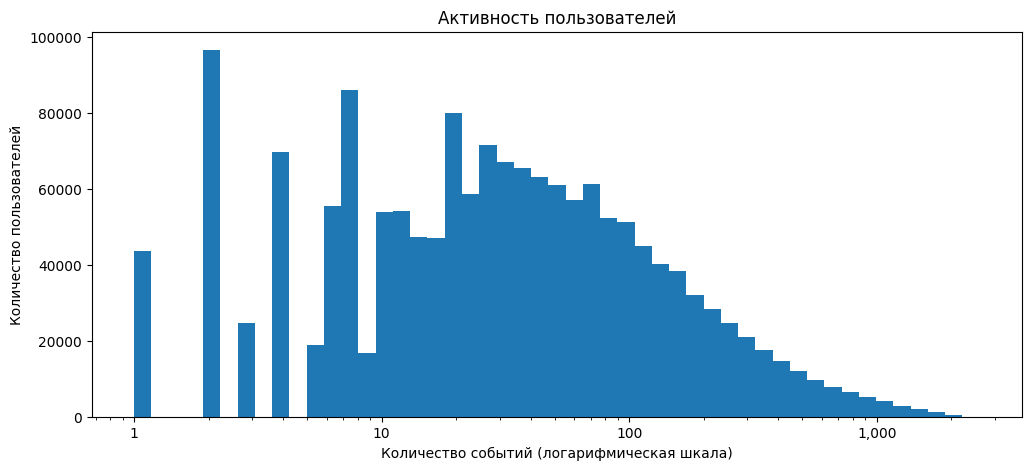

In [35]:
user_activity = user_stats["n_events"].to_numpy()
bins = np.logspace(0, np.log10(user_activity.max()) + 0.01, 50)
plt.hist(user_activity, bins=bins)
plt.xscale("log")
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.title("Активность пользователей")
plt.xlabel("Количество событий (логарифмическая шкала)")
plt.ylabel("Количество пользователей")
plt.show()

Считаем количество событий и кликов у каждого товара.

In [36]:
item_stats = lazy_events.group_by("item_id").agg(
  pl.len().alias("n_events"),
  (pl.col("action_type") == "click").sum().alias("n_clicks"),
).collect(engine="streaming")
display(item_stats.select("n_events", "n_clicks").describe())

statistic,n_events,n_clicks
str,f64,f64
"""count""",2.325409e6,2.325409e6
"""null_count""",0.0,0.0
"""mean""",56.096419,1.622121
"""std""",2767.967229,95.745276
"""min""",1.0,0.0
"""25%""",1.0,0.0
"""50%""",2.0,0.0
"""75%""",7.0,0.0
"""max""",1.346072e6,68224.0


Считаем долю событий у 1% товаров с наибольшим числом событий.

In [37]:
print("Товаров в событиях:", item_stats.height)
top_items_count = int(np.ceil(item_stats.height * 0.01))
top_items = item_stats.sort("n_events", descending=True).head(top_items_count)
print("Доля событий у 1% товаров с наибольшим числом событий:", top_items["n_events"].sum() / n_events)

Товаров в событиях: 2325409
Доля событий у 1% товаров с наибольшим числом событий: 0.8376467377197765


Смотрим распределение популярности товаров.

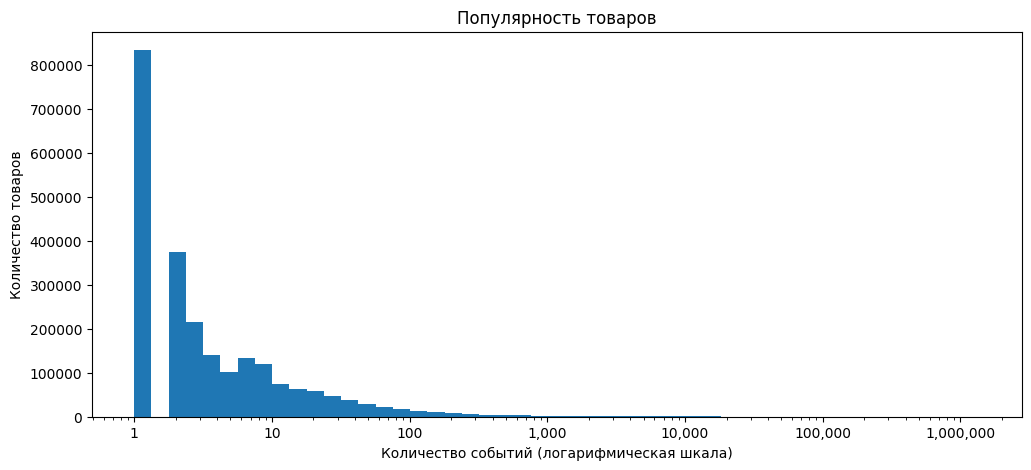

In [38]:
item_activity = item_stats["n_events"].to_numpy()
bins = np.logspace(0, np.log10(item_activity.max()) + 0.01, 50)
plt.hist(item_activity, bins=bins)
plt.xscale("log")
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.title("Популярность товаров")
plt.xlabel("Количество событий (логарифмическая шкала)")
plt.ylabel("Количество товаров")
plt.show()

Проверяем наличие товаров из событий в каталоге.

In [39]:
known_items = df_items.select("item_id").drop_nulls().unique()
missing_items = item_stats.join(known_items, on="item_id", how="anti")
print("Товаров без записи в items:", missing_items.height)
print("Событий с неизвестными товарами:", missing_items["n_events"].sum())

Товаров без записи в items: 0
Событий с неизвестными товарами: 0


Проверяем, есть ли товары каталога без событий.

In [40]:
active_item_ids = item_stats.select("item_id")
unused_items = known_items.join(active_item_ids, on="item_id", how="anti")
print("Товаров каталога без событий:", unused_items.height)

Товаров каталога без событий: 0


Отбираем пользователей с событиями marketplace.

In [41]:
marketplace_users = user_stats.select("user_id")
active_users = df_users.join(marketplace_users, on="user_id", how="semi")

Смотрим распределение пользователей по регионам и социально-демографическим группам.

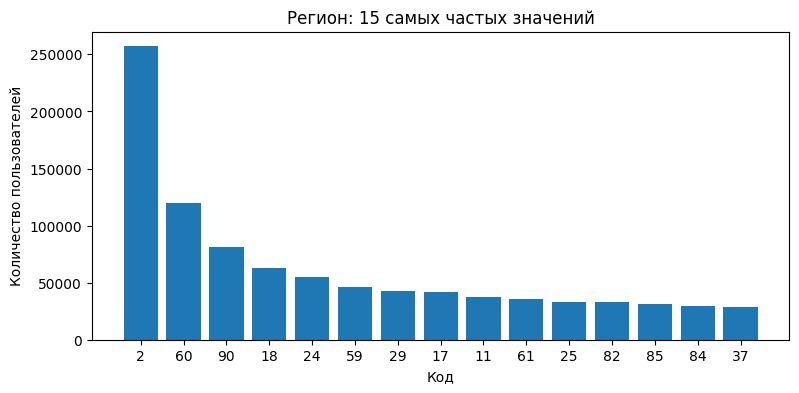

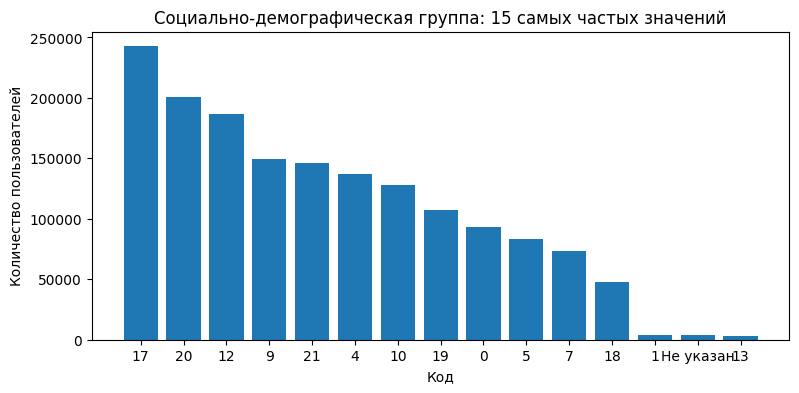

In [42]:
for column, title in [("region", "Регион"), ("socdem_cluster", "Социально-демографическая группа")]:
  counts = active_users.group_by(column).len()
  counts = counts.sort("len", descending=True).head(15)
  labels = counts[column].cast(pl.String).fill_null("Не указан").to_list()

  plt.figure(figsize=(9, 4))
  plt.bar(labels, counts["len"].to_list())
  plt.title(title + ": 15 самых частых значений")
  plt.xlabel("Код")
  plt.ylabel("Количество пользователей")
  plt.show()

Считаем долю пар пользователь–товар с событиями по всему marketplace. Для экономии памяти обрабатываем пользователей группами.

In [44]:
pairs_count = 0

for group in range(20):
    group_events = lazy_events.filter(pl.col("user_id").hash(seed=42) % 20 == group)
    group_pairs = group_events.select(pl.struct("user_id", "item_id").n_unique()).collect(engine="streaming").item()
    pairs_count += group_pairs

users_count = user_stats.height
items_count = item_stats.height
possible_pairs = users_count * items_count
share = pairs_count / possible_pairs * 100

print("Пользователей:", users_count)
print("Товаров:", items_count)
print("Пар с взаимодействиями:", pairs_count)
print("Доля пар с взаимодействиями:", round(share, 4), "%")

Пользователей: 1616763
Товаров: 2325409
Пар с взаимодействиями: 86144047
Доля пар с взаимодействиями: 0.0023 %


## 6. Другие домены и возможность объединения

Подключаем события retail и offers, а также отзывы о брендах из reviews.

In [45]:
lazy_retail = pl.scan_parquet(os.path.join(DATASET_PATH, "retail", "events", "*.pq"))
lazy_offers = pl.scan_parquet(os.path.join(DATASET_PATH, "offers", "events", "*.pq"))
lazy_reviews = pl.scan_parquet(os.path.join(DATASET_PATH, "reviews", "*.pq"))

Сравниваем число событий, пользователей и период наблюдений в четырех доменах.

In [46]:
domain_stats = []
for domain, data in [("marketplace", lazy_events), ("retail", lazy_retail), ("offers", lazy_offers), ("reviews", lazy_reviews)]:
  stats = data.select(
    pl.len().alias("events"),
    pl.col("user_id").drop_nulls().n_unique().alias("users"),
    pl.col("timestamp").dt.total_days().min().alias("first_day"),
    pl.col("timestamp").dt.total_days().max().alias("last_day"),
  ).collect(engine="streaming")
  stats = stats.with_columns(pl.lit(domain).alias("domain"))
  domain_stats.append(stats)

summary = pl.concat(domain_stats).select("domain", "events", "users", "first_day", "last_day")
display(summary)

domain,events,users,first_day,last_day
str,u32,u32,i64,i64
"""marketplace""",130447117,1616763,1082,1308
"""retail""",267043972,140062,1082,1308
"""offers""",633207032,2216762,1082,1308
"""reviews""",363970,103834,1082,1308


Смотрим, какие действия есть в retail.

In [47]:
retail_actions = lazy_retail.group_by("action_type").len().collect(engine="streaming")
display(retail_actions.sort("len", descending=True))

action_type,len
str,u32
"""view""",253468410
"""order""",7433721
"""added_to_cart""",3852145
"""click""",2289696


Смотрим, какие действия есть в offers.

In [48]:
offers_actions = lazy_offers.group_by("action_type").len().collect(engine="streaming")
display(offers_actions.sort("len", descending=True))

action_type,len
str,u32
"""view""",613449332
"""click""",16105440
"""clickout""",3353277
"""like""",298983


Смотрим распределение оценок в reviews.

In [49]:
ratings = lazy_reviews.group_by("rating").len().collect(engine="streaming")
ratings = ratings.with_columns((pl.col("len") / pl.col("len").sum()).alias("share"))
display(ratings.sort("rating"))

rating,len,share
u8,u32,f64
1,9955,0.027351
2,4628,0.012715
3,15089,0.041457
4,36306,0.09975
5,297992,0.818727


Получаем уникальные ID пользователей каждого домена.

In [50]:
retail_users = lazy_retail.select("user_id").drop_nulls().unique().collect(engine="streaming")
offers_users = lazy_offers.select("user_id").drop_nulls().unique().collect(engine="streaming")
reviews_users = lazy_reviews.select("user_id").drop_nulls().unique().collect(engine="streaming")

Считаем общих пользователей с marketplace.

In [51]:
common_retail_users = marketplace_users.join(retail_users, on="user_id", how="inner").height
common_offers_users = marketplace_users.join(offers_users, on="user_id", how="inner").height
common_reviews_users = marketplace_users.join(reviews_users, on="user_id", how="inner").height

Сравниваем доли общих пользователей: от пользователей marketplace и от пользователей второго домена.

In [52]:
user_overlap = pl.DataFrame({
  "domain": ["retail", "offers", "reviews"],
  "other_users": [retail_users.height, offers_users.height, reviews_users.height],
  "common_users": [common_retail_users, common_offers_users, common_reviews_users],
})
user_overlap = user_overlap.with_columns(
  (pl.col("common_users") / marketplace_users.height).alias("share_marketplace"),
  (pl.col("common_users") / pl.col("other_users")).alias("share_other"),
)
display(user_overlap)

domain,other_users,common_users,share_marketplace,share_other
str,i64,i64,f64,f64
"""retail""",140062,127080,0.078602,0.907312
"""offers""",2216762,1356870,0.839251,0.612095
"""reviews""",103834,77681,0.048047,0.748127


Читаем ID товаров и брендов из каталогов retail и offers.

In [53]:
retail_path = os.path.join(DATASET_PATH, "retail", "items.pq")
offers_path = os.path.join(DATASET_PATH, "offers", "items.pq")
catalog_columns = ["item_id", "brand_id"]
retail_catalog = pl.read_parquet(retail_path, columns=catalog_columns)
offers_catalog = pl.read_parquet(offers_path, columns=catalog_columns)
retail_items = retail_catalog.select("item_id").drop_nulls().unique()
offers_items = offers_catalog.select("item_id").drop_nulls().unique()

Проверяем, есть ли одинаковые ID товаров в разных доменах.

In [54]:
common_retail_items = known_items.join(retail_items, on="item_id", how="inner").height
common_offers_items = known_items.join(offers_items, on="item_id", how="inner").height
print("Общих item_id marketplace и retail:", common_retail_items)
print("Общих item_id marketplace и offers:", common_offers_items)

Общих item_id marketplace и retail: 0
Общих item_id marketplace и offers: 0


Получаем уникальные ID брендов каждого домена.

In [55]:
retail_brands = retail_catalog.select("brand_id").drop_nulls().unique()
offers_brands = offers_catalog.select("brand_id").drop_nulls().unique()
reviews_brands = lazy_reviews.select("brand_id").drop_nulls().unique().collect(engine="streaming")

Считаем общие бренды с marketplace.

In [56]:
common_retail_brands = marketplace_brands.join(retail_brands, on="brand_id", how="inner").height
common_offers_brands = marketplace_brands.join(offers_brands, on="brand_id", how="inner").height
common_reviews_brands = marketplace_brands.join(reviews_brands, on="brand_id", how="inner").height

Смотрим число общих брендов и их доли в каждом домене.

In [57]:
brand_overlap = pl.DataFrame({
  "domain": ["retail", "offers", "reviews"],
  "other_brands": [retail_brands.height, offers_brands.height, reviews_brands.height],
  "common_brands": [common_retail_brands, common_offers_brands, common_reviews_brands],
})
brand_overlap = brand_overlap.with_columns(
  (pl.col("common_brands") / marketplace_brands.height).alias("share_marketplace"),
  (pl.col("common_brands") / pl.col("other_brands")).alias("share_other"),
)
print("Брендов marketplace:", marketplace_brands.height)
display(brand_overlap)

Брендов marketplace: 231


domain,other_brands,common_brands,share_marketplace,share_other
str,i64,i64,f64,f64
"""retail""",8,1,0.004329,0.125
"""offers""",5683,73,0.316017,0.012845
"""reviews""",24467,97,0.419913,0.003965


## 7. Выводы по результатам EDA

В marketplace содержится 130,45 млн событий за 227 дней, 1,62 млн пользователей и 2,33 млн товаров от 231 бренда. В данных есть действия пользователей, время, поверхность и ОС, а также категории товаров, цена, эмбеддинги, регион и социально-демографическая группа пользователей.

- Все пользователи и товары из событий найдены в соответствующих таблицах, все бренды каталога есть в таблице брендов. Товаров без событий в этом наборе нет. Полных дублей событий не обнаружено.

- Больше всего пропусков в категориях товаров. Категория отсутствует у 41,56%, подкатегория у 53,02% товаров. Такие товары сохраняем, пропуски можно выделить в группу "Не указано". В профилях пользователей регион отсутствует у 1,37%, социально-демографическая группа у 0,22%.

- Эмбеддинги товаров заполнены почти полностью и отсутствуют только у 73 товаров. У брендов пропусков значительно больше, эмбеддинга нет в 192 из 236 строк таблицы, что составляет 81,36%.

- У бренда 37799 шесть записей. Одна содержит пропуск эмбеддинга, остальные пять содержат разные эмбеддинги. Полных дублей среди них нет, поэтому строки сохраняем.

- Большинство событий приходится на просмотры (96,70%), доля кликов составляет 2,89%. У 66,05% пользователей за весь период не было кликов, хотя другие взаимодействия были. Данных о покупках в marketplace нет, переход clickout не подтверждает покупку. Пропуски поверхности относятся к лайкам, поэтому такие события сохраняем.

- Активность распределена неравномерно. У половины пользователей не больше 28 событий, при этом 1% самых активных пользователей дает 14,68% событий. У половины товаров не больше двух событий, а 1% товаров с наибольшим числом событий получает 83,76% всех событий. Небольшое количество взаимодействий у многих товаров может затруднить построение рекомендаций.

- Пользователи взаимодействуют лишь с небольшой частью товаров. Во всем marketplace найдено 86,14 млн уникальных пар пользователь–товар. Это составляет 0,0023% всех возможных сочетаний пользователей и товаров.

- Цена отсутствует у 0,12% товаров, заполненные значения лежат в диапазоне от −10 до 10. Отрицательные значения связаны с преобразованием данных перед публикацией, точная формула неизвестна, поэтому значения не трактуем как рубли и не удаляем только из-за знака.

- Больше всего общих пользователей у marketplace с offers, там встречаются 83,93% пользователей marketplace. С retail пересекаются 7,86%, с reviews 4,80%. Совпадающих ID товаров с offers и retail нет. При этом с offers есть 73 общих бренда, с reviews 97, с retail 1.